In [1]:
from cis.data_io.products.AProduct import AProduct
from cis.data_io.Coord import Coord, CoordList
from cis.data_io.ungridded_data import UngriddedData
from cis.data_io.ungridded_data import Metadata
import cis.data_io.netcdf as netcdf
from cis.time_util import PartialDateTime
from datetime import datetime, timedelta
import logging
from pyhdf import SD
import numpy as np
import xarray as xr
import subprocess

In [5]:
import xesmf as xe

In [25]:
data_initial = xr.open_mfdataset('/wolke_scratch/dnikolo/CLAAS_Data/np/2008/01/01/CPPin20080101*.nc')

In [17]:
init_grid = xr.load_dataset("/wolke_scratch/dnikolo/dump/regrided_data/aux_file.nc", decode_times=False)

In [37]:
init_grid['mask'] = xr.where(init_grid['lat'] > 0,init_grid['lat'],0)

In [38]:
final_grid = xe.util.grid_global(1.0, 1.0)

In [39]:
regridder = xe.Regridder(init_grid, final_grid, 'bilinear')

In [21]:
import matplotlib.pyplot as plt

In [28]:
regrided_data = regridder(data_initial['cph'])

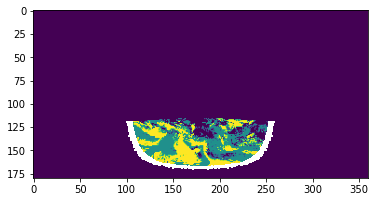

In [33]:
plt.imshow(regrided_data[4])

In [ ]:
cis.io

In [2]:
import os
os.environ["CIS_PLUGIN_HOME"] = "/wolke_scratch/dnikolo/MSGI/plugin"  # the directory that contains cis_claas_3_plugin.py
import cis  # import AFTER setting the env var

## Test Aggregation

In [3]:
data = cis.read_data_list(['/wolke_scratch/dnikolo/CLAAS_Data/np/2008/01/01/CPPin2008010100*.nc','/wolke_scratch/dnikolo/CLAAS_Data/np/2008/01/01/CPPin2008010101*.nc'],'cph',product="SEVIRI_L2_CLAAS")

In [3]:
data = cis.read_data(['/wolke_scratch/dnikolo/CLAAS_Data/np/2008/01/01/CPPin20080101*.nc'],'cph',product="SEVIRI_L2_CLAAS_HDF")

In [ ]:
data.coords()[0].data

array([1.1991456e+09, 1.1991456e+09, 1.1991456e+09, ..., 1.1991483e+09,
       1.1991483e+09, 1.1991483e+09])

In [4]:
agg_data = data.aggregate( x=slice(-81, 81, 1), y=slice(-81, 81, 1),how='mean')

/home/dnikolo/.conda/envs/cis_env9/lib/python3.9/site-packages/cis/collocation/data_index.py:79: FutureWarning: arrays to stack must be passed as a "sequence" type such as list or tuple. Support for non-sequence iterables such as generators is deprecated as of NumPy 1.16 and will raise an error in the future.
  indices = np.vstack(


In [ ]:
agg_data.

[<cis 'GriddedData' of Cloud_Top_Phase / (unknown)         (time: 1; latitude: 160; longitude: 160)>]

In [ ]:
agg_data = data.aggregate(time=[PartialDateTime(year=2008,month=1,day=1), timedelta(hours=1)], x=slice(-80, 80, 1), y=slice(-80, 80, 1),how='mean')


In [ ]:
# agg_data = data.aggregate(T=slice(datetime(2008, 1, 1, 0, 0), datetime(2008, 1, 1, 1, 0, 0), timedelta(minutes=30)), x=slice(-90, 90, 1), y=slice(-80, 80, 1),how='mean')

In [ ]:
dt = PartialDateTime(minutes=30)
dt.range()

(datetime.datetime(2008, 1, 1, 0, 0), datetime.datetime(2008, 1, 1, 0, 59, 59))

In [7]:
import matplotlib.pyplot as plt

In [ ]:
agg_data.data.shape

(2832, 160, 180)

In [17]:
agg_data[0].coords()[0]

<DimCoord: time / (seconds since 1970-01-01 00:00:00)  [...]+bounds>

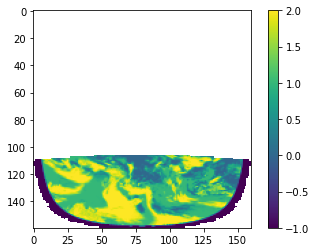

In [10]:
plt.imshow(agg_data[0].data[0],interpolation=None)
plt.colorbar()

In [ ]:

from cis.data_io.products.AProduct import AProduct
from cis.data_io.Coord import Coord, CoordList
from cis.data_io.ungridded_data import UngriddedData
from cis.data_io.ungridded_data import Metadata
import cis.data_io.hdf as hdf
import logging
from pyhdf import SD
import numpy as np

class SEVIRI_L2_CLAAS_HDF(AProduct):
    """
    Reads cloud top temperature variable from a CMSAF (CTX version 001) HDF file containing non CF compliant metadata.
    Applies scale and offset to data.
    Masks fill values.
    Creates variable metadata.
    Reads latitude and longitude values from a separate HDF file.
    Returns data, metadata and coordinates.
    """

    def get_file_signature(self):
        #"Returns a list of regular expressions, which are used to decided which files require this plugin."
        
        return [r'.*/np/.*/CPPin.*\.nc$']
    
    def create_data_object(self, filenames, variable):
        #"Read in and return the relevant data, metadata and coords for the specified filename."
        logging.debug("Creating data object for variable " + variable)
        # reading coordinates
        coords = self.create_coords(filenames, variable)
        # reading variables
        variables=[variable,'mask']
        sdata, _ = hdf.read(filenames, variables)

        # retrieve variable
        var = sdata[variable]
        var_data = hdf.read_data(var,"SD")
        
	    # apply offset to variable
        # var_data = var_data * 0.01
        
        # mask variable fill values
        var_data = np.ma.masked_less_equal(var_data ,0.0)	    
        
        # # read mask
        # cloud_mask = sdata['mask']
        # cloud_mask = hdf.read_data(cloud_mask,"SD")
        
        # apply mask to variable
        # var_data = np.ma.array(var_data, mask = (cloud_mask != 100))
        
        # create variable metadata
        metadata = Metadata(name='Cloud_Top_Phase',units='')
       
        logging.info(type(var_data))
        logging.info(type(metadata))
        logging.info(type(coords))
    
        return UngriddedData(var_data,metadata,coords)

    def create_coords(self, filenames, variable=None):
	#"Read in the relevant coordinates for the specified file and return them as a list."

        # list of coordinates to be read in
        coordinates = ['lat','lon']
        logging.info("Listing coordinates: " + str(coordinates))	    
        
        # in this case, the coord information is in a separate file
        aux_path=['/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc']
                
                
        aux_data = netcdf.read(aux_path[0],coordinates)
        lat = aux_data['lat']
        lon = aux_data['lon']

        # mask out fill values
        lat_data = netcdf.get_data(lat)[0]
        lon_data = netcdf.get_data(lon)[0]

	    # create metedata
        logging.info("gathering coordinates metadata")
        lat_metadata = netcdf.get_metadata(lat)
        lon_metadata = netcdf.get_metadata(lon)

	    # create x and y coord objects to be passed back to CIS
        lon_coord = Coord(np.tile(lon_data,len(filenames)), lon_metadata,'X')
        lat_coord = Coord(np.tile(lat_data,len(filenames)), lat_metadata,'Y')

        return CoordList([lat_coord,lon_coord])
 


In [8]:
import logging
import h5py
import numpy as np
from cis.data_io.ungridded_data import UngriddedData, Metadata

class SEVIRI_L2_CLAAS_HDF(AProduct):
    """
    Reads cloud top temperature variable from a CMSAF (CTX version 001) HDF file containing non CF compliant metadata.
    Applies scale and offset to data.
    Masks fill values.
    Creates variable metadata.
    Reads latitude and longitude values from a separate HDF file.
    Returns data, metadata and coordinates.
    """

    def get_file_signature(self):
        #"Returns a list of regular expressions, which are used to decided which files require this plugin."
        
        return [r'.*/np/.*/CPPin.*\.nc$']
    
    @staticmethod
    def _find_dataset(h5obj, target_name):
        """Find a dataset by full path or by leaf name anywhere in the file."""
        # Direct path
        if target_name in h5obj and isinstance(h5obj[target_name], h5py.Dataset):
            return h5obj[target_name]

        matches = []
        def _visitor(name, obj):
            if isinstance(obj, h5py.Dataset) and name.split("/")[-1] == target_name:
                matches.append(obj)
        h5obj.visititems(_visitor)

        if not matches:
            raise KeyError(f"Dataset '{target_name}' not found in HDF5 file.")
        if len(matches) > 1:
            logging.warning(f"Multiple datasets named '{target_name}' found; using the first at {matches[0].name}")
        return matches[0]

    def create_data_object(self, filenames, variable):
        logging.debug("Creating data object (h5py, all files) for variable " + variable)

        # Ensure we have a list of files
        if isinstance(filenames, (str, bytes)):
            filenames = [filenames]

        # Let your existing logic build coordinates for ALL files
        coords = self.create_coords(filenames, variable)

        # Read and concatenate data from every file
        arrays = []
        for fn in filenames:
            with h5py.File(fn, "r") as f:
                ds = self._find_dataset(f, variable)
                data = ds[()]  # numpy array

                # Keep dtype; just ensure it's numeric before masking comparison
                if not np.issubdtype(data.dtype, np.number):
                    data = data.astype(np.float32)

                # DO NOT apply scale/offset (matches your original commented-out behavior)

                # Mask fill (original behavior): <= 0.0
                data = np.ma.masked_less_equal(data, 0.0)

                arrays.append(data)

        # Try to concatenate along the first axis if shapes align; otherwise flatten+stack
        try:
            var_data = np.ma.concatenate(arrays, axis=0)
        except Exception:
            logging.warning("Could not concatenate along axis=0; falling back to 1D stacking.")
            arrays_flat = [a.ravel() for a in arrays]
            var_data = np.ma.concatenate(arrays_flat, axis=0)

        # Keep your original metadata exactly
        metadata = Metadata(name='Cloud_Top_Phase', units='')

        logging.info(type(var_data))
        logging.info(type(metadata))
        logging.info(type(coords))

        return UngriddedData(var_data, metadata, coords)

    def create_coords(self, filenames, variable=None):
	#"Read in the relevant coordinates for the specified file and return them as a list."

        # list of coordinates to be read in
        coordinates = ['lat','lon']
        logging.info("Listing coordinates: " + str(coordinates))	    
        
        # in this case, the coord information is in a separate file
        aux_path=['/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc']
                
                
        aux_data = netcdf.read(aux_path[0],coordinates)
        lat = aux_data['lat']
        lon = aux_data['lon']

        # mask out fill values
        lat_data = netcdf.get_data(lat)[0]
        lon_data = netcdf.get_data(lon)[0]

	    # create metedata
        logging.info("gathering coordinates metadata")
        lat_metadata = netcdf.get_metadata(lat)
        lon_metadata = netcdf.get_metadata(lon)

	    # create x and y coord objects to be passed back to CIS
        lon_coord = Coord(np.tile(lon_data,len(filenames)), lon_metadata,'X')
        lat_coord = Coord(np.tile(lat_data,len(filenames)), lat_metadata,'Y')

        return CoordList([lat_coord,lon_coord])


In [6]:
import importlib
importlib.reload(cis)

<module 'cis' from '/home/dnikolo/.conda/envs/cis_env9/lib/python3.9/site-packages/cis/__init__.py'>

In [9]:
a = SEVIRI_L2_CLAAS_HDF()
a.create_data_object(['/wolke_scratch/dnikolo/CLAAS_Data/np/2008/01/01/CPPin20080101001500405SVMSG01MD.nc'],'cph')

<cis 'UngriddedData' of Ungridded data: Cloud_Top_Phase / (unknown) 
>

In [ ]:
class SEVIRI_L2_CLAAS(AProduct):
    """
    Reads cloud top temperature variable from a CMSAF (CTX version 001) netcdf file. 
    Applies scale and offset to data.
    Masks fill values.
    Creates variable metadata.
    Reads latitude and longitude values from a separate HDF file.
    Returns data, metadata and coordinates.
    """

    def get_file_signature(self):
        #"Returns a list of regular expressions, which are used to decided which files require this plugin."
        
        return [r'*/np/*CTX*.nc']
    

    def create_data_object(self, filenames, variable):
        coords = self.create_coords(filenames, variable)

        # by_coords is usually fine; use concat_dim='time' with combine='nested' if needed
        ds = xr.open_mfdataset(filenames, combine="nested",concat_dim="time")  # requires dask installed
        var_data = ds[variable].load().data  # NumPy/NumPy-masked array

        metadata = Metadata(name='Cloud_Top_Temperature', units=str(ds[variable].attrs.get('units', 'K')))
        return UngriddedData(var_data, metadata, coords)

    def create_coords(self, filenames, variable=None):
	#"Read in the relevant coordinates for the specified file and return them as a list."

        # list of coordinates to be read in
        coordinates = ['lat','lon']
        logging.info("Listing coordinates: " + str(coordinates))	    
        
        # in this case, the coord information is in a separate file
        aux_path=['/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc']
                
                
        aux_data = netcdf.read(aux_path[0],coordinates)
        lat = aux_data['lat']
        lon = aux_data['lon']

        # mask out fill values
        lat_data = netcdf.get_data(lat)[0]
        lon_data = netcdf.get_data(lon)[0]

	    # create metedata
        logging.info("gathering coordinates metadata")
        lat_metadata = netcdf.get_metadata(lat)
        lon_metadata = netcdf.get_metadata(lon)

	    # create x and y coord objects to be passed back to CIS
        lon_coord = Coord(np.tile(lon_data,len(filenames)), lon_metadata,'X')
        lat_coord = Coord(np.tile(lat_data,len(filenames)), lat_metadata,'Y')

        return CoordList([lat_coord,lon_coord])


In [ ]:
class SEVIRI_L2_CLAAS(AProduct):
    """
    Reads cloud top temperature variable from a CMSAF (CTX version 001) netcdf file. 
    Applies scale and offset to data.
    Masks fill values.
    Creates variable metadata.
    Reads latitude and longitude values from a separate HDF file.
    Returns data, metadata and coordinates.
    """

    def get_file_signature(self):
        #"Returns a list of regular expressions, which are used to decided which files require this plugin."
        
        return r'.*/np/.*/CPPin.*\.nc$'
    
    def create_data_object(self, filenames, variable):
        def convert_to_classic(input_path, output_path):
            """
            Use the nccopy utility to convert input_path (possibly NetCDF4) to a classic-format file
            at output_path.
            """
            # "-k classic" means classic/netCDF3 model (or classic model) for the output
            cmd = [
                "cdo",
                "-f", "nc4c","-copy","-selname,cph",
                input_path,
                output_path
            ]
            try:
                subprocess.run(cmd, check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
            except subprocess.CalledProcessError as e:
                raise RuntimeError(f"nccopy conversion failed: {e.stderr.decode()}") from e
        #"Read in and return the relevant data, metadata and coords for the specified filename."
        logging.debug("Creating data object for variable " + variable)
        # reading coordinates
        temp_filenames =[]
        for filename in filenames:
            out_filename = os.path.join("/wolke_scratch/dnikolo/dump/classic_dataset",os.path.basename(filename))
            convert_to_classic(filename,out_filename)
            temp_filenames.append(out_filename)
        # reading variables
        coords = self.create_coords(filenames, variable)
        
        variables=[variable]
        sdata = netcdf.read_many_files(temp_filenames, variables, dim ='time')

        # retrieve variable
        var = sdata[variable]
        var_data = netcdf.get_data(var)
        
	    # apply offset to variable
        # var_data = var_data * 0.01
        
        # mask variable fill values
        # var_data = np.ma.masked_less_equal(var_data ,0.0)	    
        
        # # read mask
        # cloud_mask = sdata['mask']
        # cloud_mask = hdf.read_data(cloud_mask,"SD")
        
        # # apply mask to variable
        # var_data = np.ma.array(var_data, mask = (cloud_mask != 100))
        
        # create variable metadata
        metadata = Metadata(name='Cloud_Top_Temperature',standard_name="ctt",units='K')
       
        logging.info(type(var_data))
        logging.info(type(metadata))
        logging.info(type(coords))
    
        return UngriddedData(var_data,metadata,coords)

    def create_coords(self, filenames, variable=None):
	#"Read in the relevant coordinates for the specified file and return them as a list."

        # list of coordinates to be read in
        coordinates = ['lat','lon']
        logging.info("Listing coordinates: " + str(coordinates))	    
        
        # in this case, the coord information is in a separate file
        aux_filenames=['/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc']
                
                
        aux_data = netcdf.read(aux_filenames[0],coordinates)
        lat = aux_data['lat']
        lon = aux_data['lon']

        # mask out fill values
        lat_data = netcdf.get_data(lat)[0]
        lon_data = netcdf.get_data(lon)[0]

        ny, nx = lat_data.shape
        nt = len(filenames)

        # Repeat across time dimension
        lat_3d = np.broadcast_to(lat_data, (nt, ny, nx))
        lon_3d = np.broadcast_to(lon_data, (nt, ny, nx))
        # Flatten to 1-D for Ungridded coordinates
        lat_1d = lat_3d.ravel()
        lon_1d = lon_3d.ravel()

	    # create metedata
        logging.info("gathering coordinates metadata")
        # lat_metadata = netcdf.get_metadata(lat)
        lat_metadata = Metadata( name='lat', standard_name='latitude', long_name='Latitude', shape=None, units='degrees_north', range=(-81,81),missing_value=-9999.0)
        lon_metadata = Metadata( name='lon', standard_name='longitude', long_name='Longitude', shape=None, units='degrees_east', range=(-81,81),missing_value=-9999.0)

	    # Build Coord objects (name 'Y' for latitude, 'X' for longitude)
        lat_coord = Coord(lat_1d, lat_metadata, 'Y')
        lon_coord = Coord(lon_1d, lon_metadata, 'X')

        return CoordList([lat_coord, lon_coord])


In [ ]:
coordinates = ['lat','lon']
# logging.info("Listing coordinates: " + str(coordinates))	    

# in this case, the coord information is in a separate file
aux_filenames=['/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc']
        
        
aux_data = netcdf.read(aux_filenames[0],coordinates)
lat = aux_data['lat']
lon = aux_data['lon']
lat_metadata = Metadata( name='lat', standard_name='latitude', long_name='Latitude', shape=None, units='degrees_north', range=(-81,81),missing_value=-9999.0)

In [ ]:
lat_metadata.standard_name("lattitude")

TypeError: 'NoneType' object is not callable

In [ ]:
a = SEVIRI_L2_CLAAS()
a.create_data_object(['/wolke_scratch/dnikolo/CLAAS_Data/np/2008/01/01/CPPin20080101001500405SVMSG01MD.nc'],'cph')

<cis 'UngriddedData' of Ungridded data: Cloud_Top_Temperature / (K) 
>

In [ ]:
data.coords().find_standard_coords()

[None, None, None, None, None]

In [ ]:
coordinates = ['lat','lon']
filenames=['/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc']
        
        
aux_data = netcdf.read(filenames[0],coordinates)
lat = aux_data['lat']
lon = aux_data['lon']

# mask out fill values
lat_data = netcdf.get_data(lat)[0]
lon_data = netcdf.get_data(lon)[0]

V2

In [ ]:
# class SEVIRI_L2_CLAAS(AProduct):
#     """
#     Reads cloud top temperature variable from a CMSAF (CTX version 001) netcdf file. 
#     Applies scale and offset to data.
#     Masks fill values.
#     Creates variable metadata.
#     Reads latitude and longitude values from a separate HDF file.
#     Returns data, metadata and coordinates.
#     """

#     def get_file_signature(self):
#         #"Returns a list of regular expressions, which are used to decided which files require this plugin."
        
#         return r'.*/np/.*/CPPin.*\.nc$'
    
#     def create_data_object(self, filenames, variable):
#         #"Read in and return the relevant data, metadata and coords for the specified filename."
#         logging.debug("Creating data object for variable " + variable)
#         # reading coordinates
#         coords = self.create_coords(filenames, variable)
#         # reading variables
#         variables=[variable]
#         sdata = netcdf.read_many_files(filenames, variables, dim ='time')

#         # retrieve variable
#         var = sdata[variable]
#         var_data = netcdf.get_data(var)
        
# 	    # apply offset to variable
#         # var_data = var_data * 0.01
        
#         # mask variable fill values
#         # var_data = np.ma.masked_less_equal(var_data ,0.0)	    
        
#         # # read mask
#         # cloud_mask = sdata['mask']
#         # cloud_mask = hdf.read_data(cloud_mask,"SD")
        
#         # # apply mask to variable
#         # var_data = np.ma.array(var_data, mask = (cloud_mask != 100))
        
#         # create variable metadata
#         metadata = Metadata(name='Cloud_Top_Temperature',units='K')
       
#         logging.info(type(var_data))
#         logging.info(type(metadata))
#         logging.info(type(coords))
    
#         return UngriddedData(var_data,metadata,coords)

#     def create_coords(self, filenames, variable=None):
# 	#"Read in the relevant coordinates for the specified file and return them as a list."

#         # list of coordinates to be read in
#         coordinates = ['lat','lon']
#         logging.info("Listing coordinates: " + str(coordinates))	    
        
#         # in this case, the coord information is in a separate file
#         filenames=['/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc']
                
                
#         aux_data = netcdf.read(filenames[0],coordinates)
#         lat = aux_data['lat']
#         lon = aux_data['lon']

#         # mask out fill values
#         lat_data = netcdf.get_data(lat)[0]
#         lon_data = netcdf.get_data(lon)[0]

# 	    # create metedata
#         logging.info("gathering coordinates metadata")
#         lat_metadata = netcdf.get_metadata(lat)
#         lon_metadata = netcdf.get_metadata(lon)

# 	    # create x and y coord objects to be passed back to CIS
#         lon_coord = Coord(lon_data, lon_metadata,'X')
#         lat_coord = Coord(lat_data, lat_metadata,'Y')

#         return CoordList([lat_coord,lon_coord])


OLD VERSION

In [ ]:

# from cis.data_io.products.AProduct import AProduct
# from cis.data_io.Coord import Coord, CoordList
# from cis.data_io.ungridded_data import UngriddedData
# from cis.data_io.ungridded_data import Metadata
# import cis.data_io.hdf as hdf
# import logging
# from pyhdf import SD
# import numpy as np

# class SEVIRI_L2_Apollo(AProduct):
#     """
#     Reads cloud top temperature variable from a CMSAF (CTX version 001) HDF file containing non CF compliant metadata.
#     Applies scale and offset to data.
#     Masks fill values.
#     Creates variable metadata.
#     Reads latitude and longitude values from a separate HDF file.
#     Returns data, metadata and coordinates.
#     """

#     def get_file_signature(self):
#         #"Returns a list of regular expressions, which are used to decided which files require this plugin."
        
#         return [r'clouds_MET08*']
    
#     def create_data_object(self, filenames, variable):
#         #"Read in and return the relevant data, metadata and coords for the specified filename."
#         logging.debug("Creating data object for variable " + variable)
#         # reading coordinates
#         coords = self.create_coords(filenames, variable)
#         # reading variables
#         variables=[variable,'mask']
#         sdata, vdata = hdf.read(filenames, variables)

#         # retrieve variable
#         var = sdata[variable]
#         var_data = hdf.read_data(var,"SD")
        
# 	    # apply offset to variable
#         var_data = var_data * 0.01
        
#         # mask variable fill values
#         var_data = np.ma.masked_less_equal(var_data ,0.0)	    
        
#         # read mask
#         cloud_mask = sdata['mask']
#         cloud_mask = hdf.read_data(cloud_mask,"SD")
        
#         # apply mask to variable
#         var_data = np.ma.array(var_data, mask = (cloud_mask != 100))
        
#         # create variable metadata
#         metadata = Metadata(name='Cloud_Top_Temperature',units='K')
       
#         logging.info(type(var_data))
#         logging.info(type(metadata))
#         logging.info(type(coords))
    
#         return UngriddedData(var_data,metadata,coords)

#     def create_coords(self, filenames, variable=None):
# 	#"Read in the relevant coordinates for the specified file and return them as a list."

#         # list of coordinates to be read in
#         coordinates = ['latitude','longitude']
#         logging.info("Listing coordinates: " + str(coordinates))	    
        
#         # in this case, the coord information is in a separate file
#         filenames=['seviri-geolocation.hdf']
        
#         # get coord data
#         sdata,vdata = hdf.read(filenames,coordinates)
#         lat = sdata['latitude']
#         lon = sdata['longitude']
        
#         # mask out fill values
#         lat_data = hdf.read_data(lat,"SD",[999.9])
#         lon_data = hdf.read_data(lon,"SD",[999.9])

# 	    # create metedata
#         logging.info("gathering coordinates metadata")
#         lat_metadata = Metadata(name='latitude',units='degrees', missing_value=999.9)
#         lon_metadata = Metadata(name='longitude',units='degrees',missing_value=999.9)

# 	    # create x and y coord objects to be passed back to CIS
#         lon_coord = Coord(lon_data, lon_metadata,'X')
#         lat_coord = Coord(lat_data, lat_metadata,'Y')

#         return CoordList([lat_coord,lon_coord])

In [ ]:
aux_ds["lat"].values

array([[[        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        ...,
        [        nan, 30.03660171, 29.94543406, ..., 30.03658297,
                 nan,         nan],
        [        nan, 29.94014693, 29.87354071, ..., 29.94013592,
                 nan,         nan],
        [29.94347248, 29.862327  , 29.80704263, ..., 29.86231846,
         29.9434574 ,         nan]],

       [[        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        ...,
        [        nan,         nan, 30.02941061, ..., 3